# 03. Análisis de resultados

Este notebook analiza las corridas del diseño experimental. Todas las corridas medidas se ejecutaron en una misma máquina con dos GPUs NVIDIA A100 SXM4 de 80 GB, una corrida por GPU y cada una en un proceso aislado. La métrica principal es el score, definido como el promedio del macro-F1 de intención, agente y prioridad. Las decisiones de configuración (learning rate, capacidad y punto óptimo) se toman sobre el split de validación, y el split de test se usa solo para el reporte.

El diseño tiene cuatro bloques.

1. Línea base sin entrenamiento, con zero-shot y few-shot de cinco ejemplos.
2. Diseño factorial completo de LoRA con cuatro niveles de rango (2, 8, 32 y 128), tres niveles de learning rate (1e-4, 2e-4 y 5e-4) y dos réplicas. La réplica 1 usa la semilla 1234 y la réplica 2 la semilla 5678 en todas las configuraciones.
3. Tres niveles de capacidad para cada tecnología posterior a LoRA (FRoD, MiCA, Uni-LoRA y SHiRA) con dos réplicas, usando el learning rate elegido en validación en un barrido previo.
4. Validación del punto óptimo predicho por la superficie de respuesta, en una configuración que no forma parte de la grilla.

In [1]:
import sys, json
sys.path.insert(0, "../src")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from router import analisis, graficos

graficos.aplicar_estilo()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
df = analisis.cargar_corridas(Path("../results/runs"))
print(df.groupby("bloque").size().to_string())
print("GPUs", df.gpu.unique())

bloque
barrido_lr     8
base           2
lora          24
metodos       24
piloto         2
validacion     2
GPUs <StringArray>
['NVIDIA A100-SXM4-80GB']
Length: 1, dtype: str


## 1. Modelo base frente a fine-tuning

In [2]:
base = df[df.bloque == "base"].set_index("nombre")[["test_score", "test_f1_intencion", "test_f1_agente", "test_f1_prioridad", "test_json_valido", "test_exact_match", "test_acc_slots"]]
principal = df[df.bloque.isin(["lora", "metodos", "validacion"])]
resumen = analisis.resumen_por_config(principal)
mejor_por_metodo = (principal.groupby(["nombre", "capacidad", "lr"]).agg(val=("val_score", "mean")).reset_index()
                    .sort_values("val", ascending=False).groupby("nombre").head(1))
filas = []
for _, m in mejor_por_metodo.iterrows():
    g = principal[(principal.nombre == m.nombre) & (principal.capacidad == m.capacidad) & (principal.lr == m.lr)]
    filas.append(pd.Series({c: g[c].mean() for c in base.columns}, name=f"{m.nombre} {m.capacidad} lr {m.lr:g}"))
tabla = pd.concat([base, pd.DataFrame(filas)])
tabla

,test_score,test_f1_intencion,test_f1_agente,test_f1_prioridad,test_json_valido,test_exact_match,test_acc_slots
Few-shot (5),0.601,0.827,0.525,0.450,0.929,0.122,0.903
Zero-shot,0.374,0.695,0.000,0.426,0.000,0.000,0.653
SHiRA r=32 lr 0.0001,0.958,0.959,0.958,0.956,1.000,0.755,0.962
LoRA r=32 lr 0.0002,0.944,0.937,0.951,0.944,1.000,0.763,0.971
FRoD sparse_rate=0.01 lr 0.0001,0.936,0.944,0.951,0.914,1.000,0.686,0.960
Uni-LoRA theta_d_length=262144 lr 0.008,0.938,0.939,0.948,0.926,1.000,0.699,0.962
MiCA r=32 lr 0.0001,0.935,0.939,0.947,0.921,1.000,0.656,0.956


El modelo sin ajuste no resuelve la tarea. En zero-shot ninguna respuesta cumple el esquema completo porque el modelo inventa nombres de agente fuera de las cinco clases permitidas, lo que deja el macro-F1 de agente en 0 y el score en 0.374. Con cinco ejemplos en el prompt el JSON es válido en 92.9% de los casos, pero el score sube solo a 0.601 y el exact match a 0.122. Todas las tecnologías de fine-tuning llevan el JSON válido a 100% y el score a un rango entre 0.935 y 0.958, una mejora de más de 33 puntos sobre few-shot.

## 2. Diseño factorial de LoRA

La tabla muestra la media y la desviación estándar del score de test entre las dos réplicas de cada combinación de rango y learning rate. El factor alpha se fija en dos veces el rango, de modo que la escala efectiva del adapter es constante entre niveles de r.

In [3]:
lora = df[df.bloque == "lora"].copy()
tabla_lora = lora.pivot_table(index="r", columns="lr", values="test_score", aggfunc=["mean", "std"])
tabla_lora

mean               std            
lr      0.000 0.000 0.001 0.000 0.000 0.001
r                                          
2.000   0.887 0.930 0.945 0.004 0.002 0.013
8.000   0.940 0.940 0.948 0.005 0.001 0.001
32.000  0.946 0.944 0.929 0.003 0.016 0.018
128.000 0.955 0.920 0.320 0.006 0.030 0.193

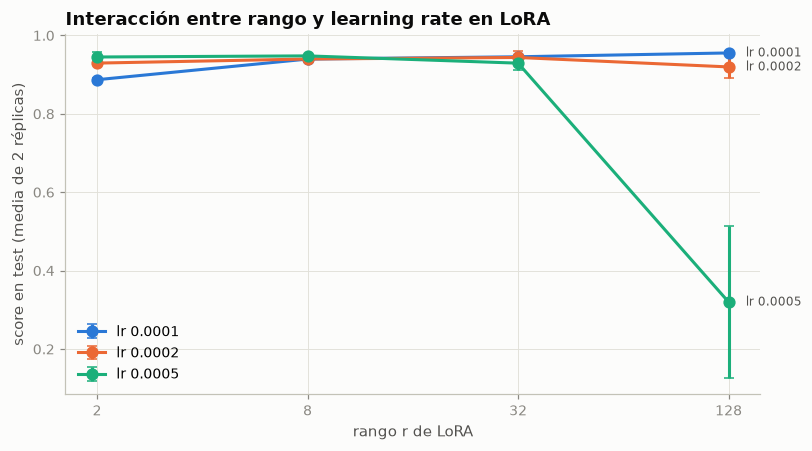

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
niveles_lr = sorted(lora.lr.unique())
for i, lr in enumerate(niveles_lr):
    g = lora[lora.lr == lr].groupby("r").test_score.agg(["mean", "std"]).reset_index()
    ax.errorbar(g.r, g["mean"], yerr=g["std"], marker="o", capsize=3, color=graficos.SERIES[i], label=f"lr {lr:g}")
    ax.text(g.r.iloc[-1] * 1.12, g["mean"].iloc[-1], f"lr {lr:g}", va="center", fontsize=8, color=graficos.TINTA_SECUNDARIA)
ax.set_xscale("log", base=2)
ax.set_xticks(sorted(lora.r.unique()), [str(int(v)) for v in sorted(lora.r.unique())])
ax.set_xlabel("rango r de LoRA")
ax.set_ylabel("score en test (media de 2 réplicas)")
ax.set_title("Interacción entre rango y learning rate en LoRA", loc="left")
ax.legend(loc="lower left")
fig.tight_layout()

In [5]:
anova = sm.stats.anova_lm(smf.ols("test_score ~ C(r) * C(lr)", data=lora).fit(), typ=2)
anova["eta2"] = anova["sum_sq"] / anova["sum_sq"].sum()
anova

,sum_sq,df,F,PR(>F),eta2
C(r),0.186,3.000,19.098,0.000,0.252
C(lr),0.115,2.000,17.734,0.000,0.156
C(r):C(lr),0.399,6.000,20.430,0.000,0.539
Residual,0.039,12.000,NaN,NaN,0.053


In [6]:
estable = lora[lora.r < 128]
anova_estable = sm.stats.anova_lm(smf.ols("test_score ~ C(r) * C(lr)", data=estable).fit(), typ=2)
anova_estable["eta2"] = anova_estable["sum_sq"] / anova_estable["sum_sq"].sum()
anova_estable

,sum_sq,df,F,PR(>F),eta2
C(r),0.002,2.000,9.802,0.005,0.263
C(lr),0.001,2.000,5.376,0.029,0.144
C(r):C(lr),0.003,4.000,8.785,0.004,0.472
Residual,0.001,9.000,NaN,NaN,0.121


El ANOVA de dos factores con réplicas muestra efectos significativos del rango, del learning rate y de su interacción, todos con p < 0.001. La interacción explica 54% de la variabilidad (eta cuadrado de 0.539) y está dominada por la divergencia del entrenamiento con r = 128 y lr = 5e-4, donde el score cae a 0.320 con una desviación de 0.193 entre réplicas. Al excluir r = 128, la interacción sigue siendo significativa (p = 0.004) y explica 47% de la variabilidad.

El patrón es consistente en toda la grilla. Los rangos bajos necesitan learning rates altos, ya que r = 2 pasa de 0.887 con lr = 1e-4 a 0.945 con lr = 5e-4. Los rangos altos rinden mejor con learning rates bajos, ya que r = 128 alcanza 0.955 con lr = 1e-4 y diverge con lr = 5e-4. Con alpha proporcional a r, un rango mayor suma más direcciones de actualización con la misma escala, por lo que un mismo learning rate produce pasos efectivos más grandes. En consecuencia, el rango y el learning rate deben elegirse en conjunto.

## 3. Superficie de respuesta y punto óptimo

Para estimar el punto óptimo se ajusta una superficie de respuesta de segundo orden sobre el score de validación, con x1 igual a log2(r) y x2 igual a log10(lr), incluyendo términos cuadráticos e interacción. Las corridas divergentes se excluyen del ajuste porque una superficie cuadrática no puede representar un colapso abrupto del entrenamiento. El punto estacionario de la superficie entrega la configuración (r*, lr*) predicha como óptima.

In [7]:
estables = lora[lora.val_score > 0.5]
modelo, (r_opt, lr_opt), es_max = analisis.ajustar_superficie(estables, "val_score")
print(modelo.summary().tables[1])
print(f"R2 {modelo.rsquared:.3f}, punto estacionario r* = {r_opt:.1f}, lr* = {lr_opt:.2e}, máximo = {es_max}")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.1232      0.724      0.170      0.867      -1.411       1.657
x1            -0.0660      0.023     -2.915      0.010      -0.114      -0.018
x2            -0.5182      0.401     -1.293      0.214      -1.368       0.331
I(x1 ** 2)    -0.0027      0.001     -3.176      0.006      -0.004      -0.001
I(x2 ** 2)    -0.0818      0.055     -1.477      0.159      -0.199       0.036
x1:x2         -0.0230      0.006     -3.620      0.002      -0.037      -0.010
R2 0.533, punto estacionario r* = 9.8, lr* = 2.33e-04, máximo = True


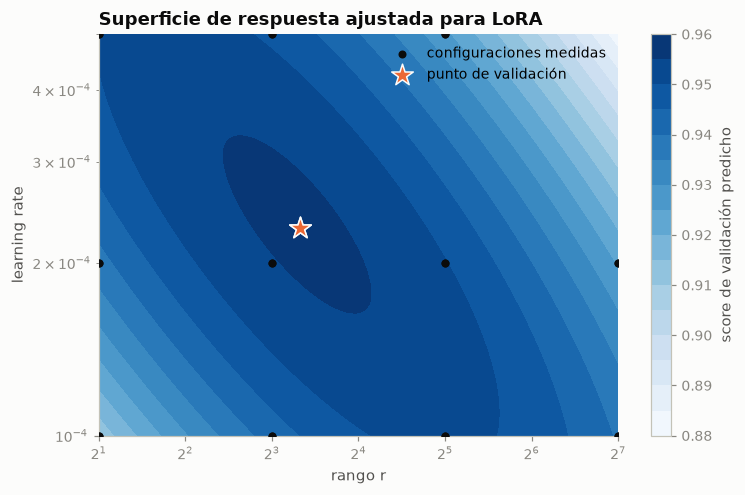

In [8]:
x1 = np.linspace(np.log2(estables.r.min()), np.log2(estables.r.max()), 120)
x2 = np.linspace(np.log10(estables.lr.min()), np.log10(estables.lr.max()), 120)
X1, X2 = np.meshgrid(x1, x2)
Z = modelo.predict(pd.DataFrame({"x1": X1.ravel(), "x2": X2.ravel()})).values.reshape(X1.shape)
fig, ax = plt.subplots(figsize=(7, 4.6))
cs = ax.contourf(2**X1, 10**X2, Z, levels=14, cmap="Blues")
fig.colorbar(cs, ax=ax, label="score de validación predicho")
ax.scatter(estables.r, estables.lr, color=graficos.TINTA, s=18, label="configuraciones medidas", zorder=3)
validacion = df[df.bloque == "validacion"]
if len(validacion):
    ax.scatter(validacion.r, validacion.lr, marker="*", s=220, color=graficos.SERIES[1], edgecolor=graficos.SUPERFICIE, label="punto de validación", zorder=4)
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xlabel("rango r")
ax.set_ylabel("learning rate")
ax.set_title("Superficie de respuesta ajustada para LoRA", loc="left")
ax.legend(loc="upper right")
ax.grid(False)
fig.tight_layout()

### Validación del óptimo

La configuración predicha se redondea a valores implementables y se ejecuta con las mismas dos semillas del diseño. Como no pertenece a la grilla, esta corrida verifica la predicción del modelo fuera de los puntos usados para ajustarlo.

In [9]:
if len(validacion):
    v = validacion.iloc[0]
    pred = modelo.predict(pd.DataFrame({"x1": [np.log2(v.r)], "x2": [np.log10(v.lr)]})).iloc[0]
    obs = validacion[["val_score", "test_score"]].agg(["mean", "std"])
    print(f"configuración validada r = {int(v.r)}, lr = {v.lr:g}")
    print(f"score de validación predicho por la superficie {pred:.3f}")
    display(obs)
    mejor_grilla = lora.groupby(["r", "lr"])[["val_score", "test_score"]].mean().sort_values("val_score", ascending=False).head(3)
    display(mejor_grilla)

configuración validada r = 10, lr = 0.00023
score de validación predicho por la superficie 0.956


,val_score,test_score
mean,0.942,0.937
std,0.012,0.005


,,val_score,test_score
r,lr,,
32.000,0.000,0.955,0.944
8.000,0.000,0.952,0.940
2.000,0.001,0.950,0.945


La superficie ajustada tiene un máximo en r* = 9.8 y lr* = 2.33e-4, con un R² de 0.533. La configuración validada fue r = 10 y lr = 2.3e-4, que no pertenece a la grilla. La superficie predijo un score de validación de 0.956 y las dos réplicas obtuvieron 0.942 ± 0.012 en validación y 0.937 ± 0.005 en test. El valor observado queda 0.014 por debajo de la predicción, una diferencia del mismo orden que la variación entre réplicas, cuya desviación estándar media en test es 0.009.

La validación confirma que el desempeño de LoRA forma una meseta. Con un learning rate adecuado, cualquier rango entre 2 y 128 obtiene entre 0.945 y 0.955 en test. Dentro de esa meseta las diferencias entre configuraciones son comparables al ruido entre semillas, por lo que el modelo cuadrático no puede localizar un óptimo más preciso que la propia meseta. En términos prácticos, seguir ajustando r o lr dentro de esa región no produce mejoras medibles.

## 4. Saturación del desempeño según los parámetros entrenables

Cada tecnología controla su capacidad con un parámetro distinto, por lo que la comparación común se hace sobre el número de parámetros entrenables en escala logarítmica. Para cada método y nivel de capacidad se toma el learning rate con mejor validación. Sobre esos puntos se ajusta una curva logística, y el codo se define como el menor número de parámetros a partir del cual multiplicar por diez la capacidad mejora el score en menos de 0.005.

In [10]:
puntos = (principal[principal.val_score > 0.5].groupby(["nombre", "capacidad", "lr", "params", "log10_params"])
          .agg(test=("test_score", "mean"), val=("val_score", "mean")).reset_index())
# Para cada método y capacidad se conserva el learning rate con mejor validación.
puntos = puntos.sort_values("val", ascending=False).groupby(["nombre", "capacidad"]).head(1)
p_sat, r2_sat = analisis.ajustar_saturacion(puntos.log10_params.values, puntos.test.values)
codo = analisis.punto_de_codo(p_sat, tolerancia=0.005)
print(f"techo {p_sat[0]:.3f}, R2 {r2_sat:.3f}, codo en 10^{codo:.2f} = {10**codo:,.0f} parámetros entrenables")
puntos.sort_values("params")[["nombre", "capacidad", "lr", "params", "val", "test"]]

techo 0.938, R2 0.968, codo en 10^5.07 = 116,944 parámetros entrenables


,nombre,capacidad,lr,params,val,test
23,Uni-LoRA,theta_d_length=4096,0.008,4096,0.688,0.656
22,Uni-LoRA,theta_d_length=32768,0.008,32768,0.860,0.864
21,Uni-LoRA,theta_d_length=262144,0.008,262144,0.940,0.938
8,LoRA,r=2,0.001,3891200,0.950,0.945
17,MiCA,r=8,0.000,7536640,0.933,0.928
20,SHiRA,r=8,0.000,15564800,0.950,0.943
12,LoRA,r=8,0.000,15564800,0.952,0.940
3,LoRA,r=10,0.000,19456000,0.942,0.937
0,FRoD,sparse_rate=0.005,0.000,22228160,0.943,0.951
16,MiCA,r=32,0.000,30146560,0.937,0.935


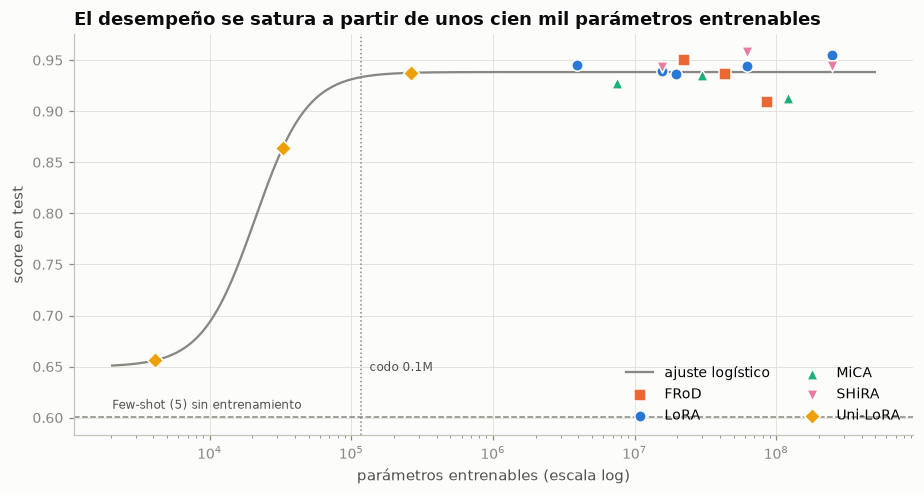

In [11]:
fig, ax = plt.subplots(figsize=(8.5, 4.6))
xs = np.linspace(puntos.log10_params.min() - 0.3, puntos.log10_params.max() + 0.3, 300)
ax.plot(10**xs, analisis.saturacion(xs, *p_sat), color=graficos.TINTA_TENUE, linewidth=1.5, label="ajuste logístico")
for nombre, g in puntos.groupby("nombre"):
    ax.scatter(g.params, g.test, s=55, marker=graficos.MARCADOR_METODO[nombre], color=graficos.COLOR_METODO[nombre], label=nombre, edgecolor=graficos.SUPERFICIE, linewidth=1, zorder=3)
ax.axvline(10**codo, color=graficos.TINTA_TENUE, linestyle=":", linewidth=1)
ax.text(10**codo * 1.15, ax.get_ylim()[0] + 0.01, f"codo {10**codo/1e6:.1f}M", fontsize=8, color=graficos.TINTA_SECUNDARIA)
for nombre_base, color in (("Few-shot (5)", graficos.TINTA_TENUE),):
    y = df[(df.bloque == "base") & (df.nombre == nombre_base)].test_score.iloc[0]
    ax.axhline(y, color=color, linestyle="--", linewidth=1)
    ax.text(10**xs.min(), y + 0.008, f"{nombre_base} sin entrenamiento", fontsize=8, color=graficos.TINTA_SECUNDARIA)
ax.set_xscale("log")
ax.set_xlabel("parámetros entrenables (escala log)")
ax.set_ylabel("score en test")
ax.set_title("El desempeño se satura a partir de unos cien mil parámetros entrenables", loc="left")
ax.legend(loc="lower right", ncol=2)
fig.tight_layout()

La curva logística ajusta bien los puntos, con un R² de 0.968. El desempeño crece rápido en la zona de Uni-LoRA, desde 0.656 con 4,096 parámetros hasta 0.864 con 32,768 y 0.938 con 262,144, y luego se estabiliza. El codo se ubica en unos 117 mil parámetros entrenables, cerca de 0.003% de los 3,660 millones de parámetros del modelo base. Por encima de ese punto, multiplicar la capacidad por diez aporta menos de 0.005 al score. Entre 4 y 250 millones de parámetros entrenables, las configuraciones estables quedan entre 0.909 y 0.958 sin una tendencia creciente.

La capacidad alta además introduce riesgos. MiCA y FRoD obtienen su peor score en su nivel de mayor capacidad, y LoRA con r = 128 diverge cuando el learning rate es alto. Esta es la frontera a partir de la cual seguir invirtiendo capacidad en el adapter deja de ser provechoso.

## 5. Comparación de tecnologías

La tabla compara la mejor configuración de cada tecnología según validación. Los tiempos y recursos corresponden a la A100 de 80 GB. La latencia es el tiempo medio por solicitud individual con batch 1. Se reporta la mediana por método porque las dos corridas que comparten la máquina compiten por CPU y eso añade ruido a la latencia de cada corrida.

In [12]:
comp = []
for nombre, g in principal.groupby("nombre"):
    cfgs = g.groupby(["capacidad", "lr"]).val_score.mean().sort_values(ascending=False)
    cap, lr = cfgs.index[0]
    s = g[(g.capacidad == cap) & (g.lr == lr)]
    comp.append({"método": nombre, "config (mejor en val)": f"{cap}, lr {lr:g}", "params": int(s.params.iloc[0]),
                 "test media": s.test_score.mean(), "test std": s.test_score.std(), "exact match": s.test_exact_match.mean(),
                 "init min": s.init_min.mean(), "train min": s.train_min.mean(), "VRAM train GB": s.vram_train_gb.mean(),
                 "energía train Wh": s.energia_train_wh.mean(),
                 "latencia merged ms (mediana método)": g.latencia_ms.median(),
                 "latencia sin merge ms (mediana método)": g.latencia_sin_merge_ms.median()})
comparacion = pd.DataFrame(comp).sort_values("test media", ascending=False).reset_index(drop=True)
comparacion

,método,config (mejor en val),params,test media,test std,exact match,init min,train min,VRAM train GB,energía train Wh,latencia merged ms (mediana método),latencia sin merge ms (mediana método)
0,SHiRA,"r=32, lr 0.0001",62259200,0.958,0.002,0.755,1.295,3.254,31.235,20.821,"2,031.870","5,651.079"
1,LoRA,"r=32, lr 0.0002",62259200,0.944,0.016,0.763,0.041,3.309,29.577,19.496,"1,940.892","4,121.308"
2,Uni-LoRA,"theta_d_length=262144, lr 0.008",262144,0.938,0.000,0.699,0.010,3.349,25.547,18.806,"1,935.838","4,690.876"
3,FRoD,"sparse_rate=0.01, lr 0.0001",43514240,0.936,0.006,0.686,21.610,13.089,49.185,51.404,"2,063.548","86,483.379"
4,MiCA,"r=32, lr 0.0001",30146560,0.935,0.002,0.656,1.903,3.202,29.161,19.433,"1,932.025","4,168.637"


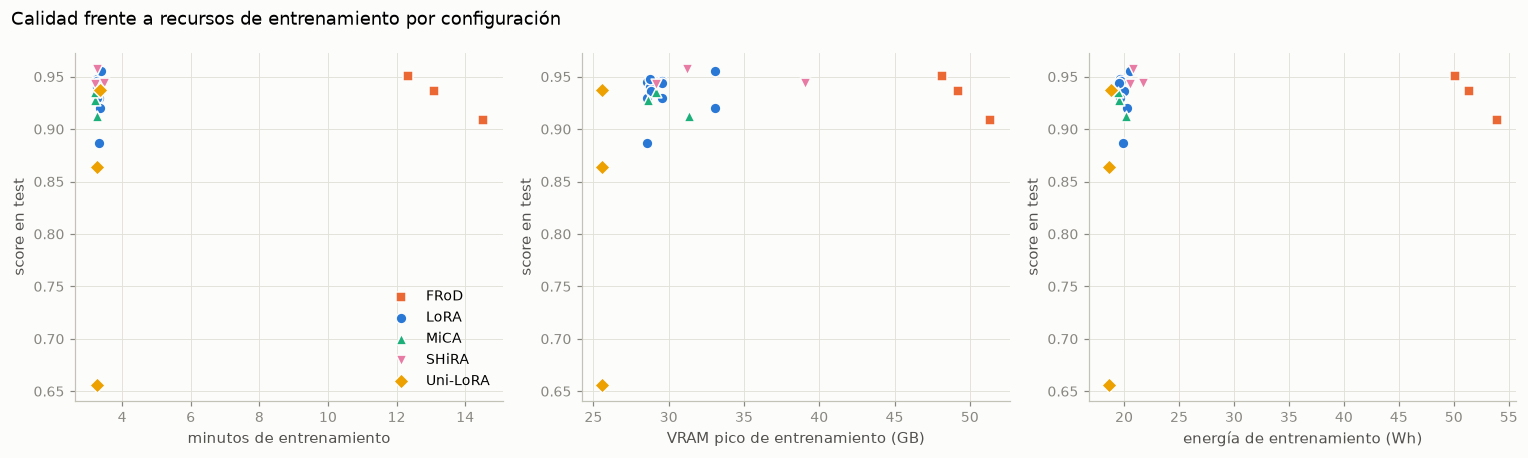

In [13]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 4.2))
cfg_metodos = analisis.resumen_por_config(principal[principal.val_score > 0.5])
for ax, (columna, etiqueta) in zip(ejes, (("train_min", "minutos de entrenamiento"), ("vram_train_gb", "VRAM pico de entrenamiento (GB)"), ("energia_train_wh", "energía de entrenamiento (Wh)"))):
    for nombre, g in cfg_metodos.groupby("nombre"):
        ax.scatter(g[columna], g["media"], s=50, marker=graficos.MARCADOR_METODO[nombre], color=graficos.COLOR_METODO[nombre], label=nombre, edgecolor=graficos.SUPERFICIE, zorder=3)
    ax.set_xlabel(etiqueta)
    ax.set_ylabel("score en test")
ejes[0].legend(loc="lower right")
fig.suptitle("Calidad frente a recursos de entrenamiento por configuración", x=0.01, ha="left", fontsize=12)
fig.tight_layout()

Las cinco tecnologías alcanzan un desempeño similar en su mejor configuración, entre 0.935 y 0.958 en test. SHiRA con r = 32 obtiene el mejor score medio (0.958) y la menor variación entre réplicas (0.002). LoRA con r = 32 obtiene 0.944 con una desviación de 0.016, por lo que su diferencia con SHiRA es del orden del ruido entre semillas. Las diferencias relevantes aparecen en los recursos.

1. Uni-LoRA logra 0.938 con 262,144 parámetros entrenables, 237 veces menos que LoRA y SHiRA con r = 32. Es el adapter más liviano para almacenar y distribuir.
2. FRoD tiene una calidad comparable, pero su inicialización tarda entre 5 y 26 minutos porque descompone las matrices de pesos en CPU. Además entrena cuatro veces más lento, usa 49 GB de VRAM frente a 25 a 31 GB de los demás métodos y consume 2.6 veces más energía. Sin fusionar, su latencia supera los 86 segundos por solicitud.
3. MiCA obtiene el menor score entre las tecnologías posteriores a LoRA. Su diseño concentra la actualización en las direcciones singulares menores con el objetivo de incorporar conocimiento nuevo, mientras que esta tarea exige aprender un formato y una política de decisión.
4. Salvo FRoD, el tiempo de entrenamiento es casi idéntico entre métodos, entre 3.2 y 3.4 minutos, y la VRAM varía poco. El costo lo dominan el forward y el backward del modelo base congelado y no el tamaño del adapter.
5. Una vez fusionados, todos los adapters tienen la latencia del modelo base, entre 1.9 y 2.1 segundos por solicitud. Sin fusionar, la latencia sube a entre 4.1 y 5.7 segundos en LoRA, MiCA, Uni-LoRA y SHiRA.

## 6. Costos

El costo de cómputo se calcula multiplicando el tiempo total de cada corrida por el precio por hora de una A100 en cuatro proveedores (`data/precios_referencia.json`). El costo de inferencia se compara con el de resolver la misma tarea mediante la API de Claude, estimando 780 tokens de entrada y 85 de salida por solicitud. El costo propio se calcula con la GPU alquilada a tiempo completo, por lo que asume que el servicio mantiene la GPU ocupada.

In [14]:
precios = json.load(open("../data/precios_referencia.json", encoding="utf-8"))
gpu_h = {k: v["usd"] for k, v in precios["gpu_hora_usd"].items()}
costos = comparacion[["método", "config (mejor en val)"]].copy()
for nombre_precio, usd in gpu_h.items():
    horas = [principal[(principal.nombre == m)].total_min.mean() / 60 for m in comparacion["método"]]
    costos[f"USD por corrida, {nombre_precio}"] = np.array(horas) * usd
costos

,método,config (mejor en val),"USD por corrida, vast_ai_a100_80gb_real","USD por corrida, colab_pro_a100_80gb","USD por corrida, colab_enterprise_a100","USD por corrida, aws_p4de_a100_80gb"
0,SHiRA,"r=32, lr 0.0001",0.124,0.081,0.382,0.372
1,LoRA,"r=32, lr 0.0002",0.098,0.064,0.301,0.294
2,Uni-LoRA,"theta_d_length=262144, lr 0.008",0.097,0.064,0.300,0.292
3,FRoD,"sparse_rate=0.01, lr 0.0001",0.734,0.482,2.264,2.206
4,MiCA,"r=32, lr 0.0001",0.131,0.086,0.405,0.395


In [15]:
gasto = df[df.gpu.str.contains("A100")]
horas_gpu = gasto.total_min.sum() / 60
print(f"corridas medidas {len(gasto)}, horas-GPU {horas_gpu:.1f}, costo de cómputo en vast.ai {horas_gpu * gpu_h['vast_ai_a100_80gb_real']:.2f} USD")
print(f"el mismo cómputo en AWS p4de costaría {horas_gpu * gpu_h['aws_p4de_a100_80gb']:.2f} USD y en Colab Pro {horas_gpu * gpu_h['colab_pro_a100_80gb']:.2f} USD")

corridas medidas 62, horas-GPU 11.6, costo de cómputo en vast.ai 13.26 USD
el mismo cómputo en AWS p4de costaría 39.87 USD y en Colab Pro 8.72 USD


In [16]:
tok_entrada, tok_salida = 780, 85
api = precios["api_usd_por_millon_tokens"]
mejor = principal[principal.nombre == comparacion["método"].iloc[0]]
ms_lote = mejor.test_gen_ms_por_ejemplo_lote.mean()
ms_individual = mejor.latencia_ms.median()
filas_inf = []
for nombre_api, p in api.items():
    filas_inf.append({"opción": nombre_api, "USD por 1000 solicitudes": 1000 * (tok_entrada * p["entrada"] + tok_salida * p["salida"]) / 1e6})
for etiqueta, ms in (("Granite ajustado en A100 propia, lotes de 32", ms_lote), ("Granite ajustado en A100 propia, una solicitud a la vez", ms_individual)):
    filas_inf.append({"opción": etiqueta, "USD por 1000 solicitudes": 1000 * ms / 1000 / 3600 * gpu_h["vast_ai_a100_80gb_real"]})
inferencia = pd.DataFrame(filas_inf)
inferencia

,opción,USD por 1000 solicitudes
0,claude_haiku_5_5,0.120
1,claude_sonnet_5_5,2.410
2,"Granite ajustado en A100 propia, lotes de 32",0.051
3,"Granite ajustado en A100 propia, una solicitud...",0.644


El cómputo total de las 62 corridas medidas fue de 11.6 horas-GPU. En vast.ai ese cómputo costó 13.26 USD. El mismo cómputo costaría 39.87 USD en AWS p4de y 8.72 USD en Colab Pro, aunque Colab no permite ejecutar dos GPUs en paralelo ni garantiza disponibilidad de A100. Una corrida de LoRA, SHiRA, MiCA o Uni-LoRA cuesta entre 0.10 y 0.13 USD en vast.ai, y una de FRoD cuesta 0.73 USD, entre seis y ocho veces más.

En inferencia, el modelo ajustado servido en una A100 propia con lotes de 32 solicitudes cuesta 0.051 USD por cada mil solicitudes. Esto es menos de la mitad que Claude Haiku 5.5 (0.120 USD) y unas 47 veces menos que Claude Sonnet 5.5 (2.410 USD). La ventaja depende de mantener la GPU ocupada, ya que atendiendo una solicitud a la vez el costo sube a 0.644 USD por mil solicitudes y supera al de Haiku. La comparación cubre solo el costo, porque el desempeño de los modelos de Claude en esta tarea no se midió. El costo de entrenar el mejor adapter, unos 0.12 USD, se recupera frente a Haiku en menos de dos mil solicitudes.

## 7. Conclusiones

1. El fine-tuning es indispensable para esta tarea. Granite 4.2 3B sin ajuste obtiene un score de 0.374 en zero-shot y 0.601 en few-shot, mientras que cualquier adapter entrenado alcanza entre 0.935 y 0.958 con 100% de JSON válido.
2. El desempeño se satura muy temprano. El codo está en unos 117 mil parámetros entrenables y, desde unos 4 millones (LoRA con r = 2), aumentar la capacidad no mejora el score. Las capacidades altas incluso aumentan el riesgo de degradación y divergencia.
3. El rango y el learning rate interactúan de forma significativa en LoRA. La superficie de respuesta predijo un óptimo en r = 9.8 y lr = 2.33e-4, y su validación fuera de la grilla obtuvo 0.937 en test, dentro de la meseta de las mejores configuraciones. La meseta, más que un punto único, es el resultado útil para elegir hiperparámetros.
4. Entre las tecnologías posteriores a LoRA, SHiRA obtuvo el mejor score y la menor variación entre semillas con el mismo costo de entrenamiento que LoRA. Uni-LoRA ofrece casi la misma calidad con 237 veces menos parámetros. FRoD no compensa su costo de inicialización, memoria y tiempo, y MiCA no aporta ventajas en una tarea de formato y clasificación.
5. El experimento completo costó 13.91 USD en vast.ai. En producción, el modelo ajustado servido en lotes cuesta menos que una API comercial, siempre que el volumen de solicitudes mantenga ocupada la GPU.